In [1]:


SID4 = 2733
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

import random
import numpy as np
import torch

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("SID4 =", SID4)
print("SEED  =", SEED)
print("SLICE =", SLICE)
print("HP_ID =", HP_ID)
print("CLS_A =", CLS_A)
print("CLS_B =", CLS_B)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

SID4 = 2733
SEED  = 2733
SLICE = 733
HP_ID = 3
CLS_A = 3
CLS_B = 7
Device: cuda


In [3]:
!pip -q install diffusers transformers accelerate

In [4]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from diffusers import AutoencoderKL

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


In [5]:
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

print("Dataset size:", len(dataset))
print("Classes:", dataset.classes)

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 167kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.12MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.3MB/s]

Dataset size: 60000
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [6]:
sample_indices = [
    (SLICE + i) % len(dataset)
    for i in range(8)
]

images = torch.stack([
    dataset[index][0]
    for index in sample_indices
]).to(device)

labels = torch.tensor([
    dataset[index][1]
    for index in sample_indices
]).to(device)

print("Selected indices:", sample_indices)
print("Image batch shape:", images.shape)
print("Labels:", labels.tolist())

Selected indices: [733, 734, 735, 736, 737, 738, 739, 740]
Image batch shape: torch.Size([8, 3, 64, 64])
Labels: [4, 5, 8, 8, 6, 5, 7, 1]


In [7]:
vae = AutoencoderKL.from_pretrained(
    "stabilityai/sd-vae-ft-mse"
).to(device)

vae.eval()

for parameter in vae.parameters():
    parameter.requires_grad = False

LATENT_SCALE = 0.18215

print("VAE loaded successfully")
print("Latent scaling factor:", LATENT_SCALE)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

VAE loaded successfully
Latent scaling factor: 0.18215


In [8]:
with torch.no_grad():
    latent_dist = vae.encode(images).latent_dist

    # Sample from the VAE latent distribution
    latents = latent_dist.sample() * LATENT_SCALE

    # Decode by undoing the scaling
    reconstructed = vae.decode(
        latents / LATENT_SCALE
    ).sample

print("Original image shape:", images.shape)
print("Latent shape:", latents.shape)
print("Reconstructed shape:", reconstructed.shape)

Original image shape: torch.Size([8, 3, 64, 64])
Latent shape: torch.Size([8, 4, 8, 8])
Reconstructed shape: torch.Size([8, 3, 64, 64])


In [9]:
reconstruction_mse = F.mse_loss(reconstructed, images)

print(f"Reconstruction MSE: {reconstruction_mse.item():.6f}")

Reconstruction MSE: 0.007643


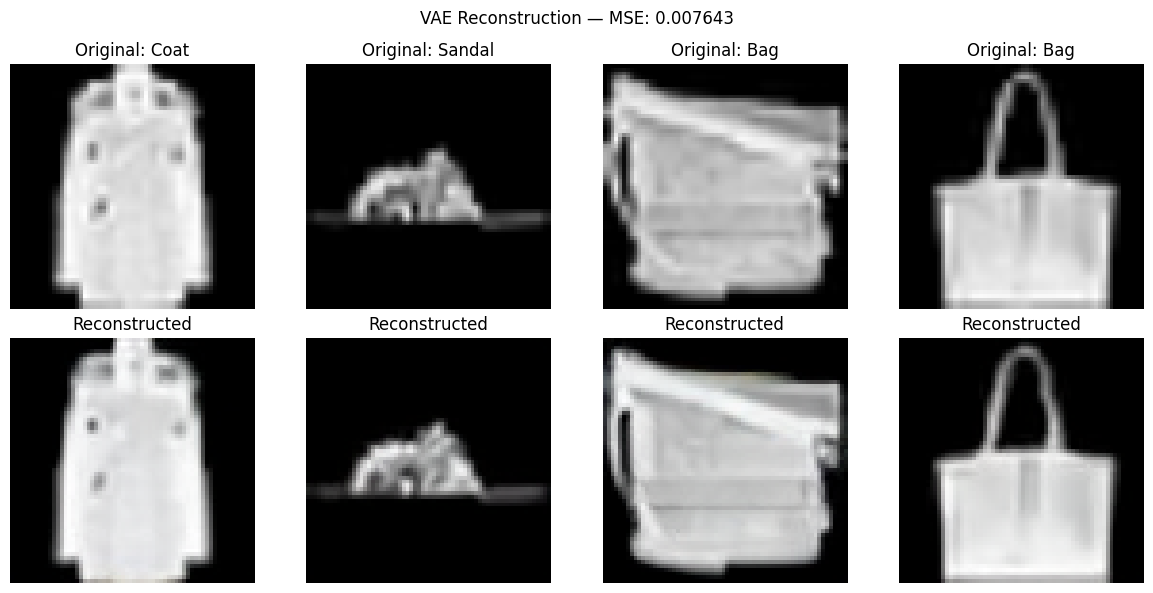

In [10]:
def denorm(x):
    return (x.clamp(-1, 1) + 1) / 2

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i in range(4):
    original = denorm(images[i]).permute(1, 2, 0).cpu().numpy()
    reconstruction = denorm(reconstructed[i]).permute(1, 2, 0).cpu().numpy()

    axes[0, i].imshow(original)
    axes[0, i].set_title(f"Original: {dataset.classes[labels[i].item()]}")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstruction)
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.suptitle(f"VAE Reconstruction — MSE: {reconstruction_mse.item():.6f}")
plt.tight_layout()
plt.show()

In [11]:
# Forward diffusion schedule

NUM_DIFFUSION_STEPS = 1000
BETA_START = 1e-4
BETA_END = 0.02

betas = torch.linspace(
    BETA_START,
    BETA_END,
    NUM_DIFFUSION_STEPS,
    device=device
)

alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - alpha_bars)

print("Number of diffusion steps:", NUM_DIFFUSION_STEPS)
print("Beta range:", betas[0].item(), "to", betas[-1].item())
print("Alpha-bar shape:", alpha_bars.shape)

Number of diffusion steps: 1000
Beta range: 9.999999747378752e-05 to 0.019999999552965164
Alpha-bar shape: torch.Size([1000])


In [12]:
def q_sample(x0, timestep, noise=None):
    """
    Sample z_t from q(z_t | z_0):

    z_t = sqrt(alpha_bar_t) * z_0
         + sqrt(1 - alpha_bar_t) * noise
    """
    if noise is None:
        noise = torch.randn_like(x0)

    sqrt_ab = sqrt_alpha_bars[timestep].view(-1, 1, 1, 1)
    sqrt_one_minus_ab = sqrt_one_minus_alpha_bars[timestep].view(
        -1, 1, 1, 1
    )

    noisy_latents = (
        sqrt_ab * x0
        + sqrt_one_minus_ab * noise
    )

    return noisy_latents, noise

In [13]:
display_timesteps = [0, 200, 500, 800, 1000]

# Use one fixed noise tensor so the comparison is fair
fixed_noise = torch.randn_like(latents)

decoded_noisy_images = []

with torch.no_grad():
    for timestep in display_timesteps:
        # Convert assignment timestep to a valid 0-based schedule index
        schedule_index = min(max(timestep - 1, 0), NUM_DIFFUSION_STEPS - 1)

        timestep_tensor = torch.full(
            (latents.shape[0],),
            schedule_index,
            device=device,
            dtype=torch.long
        )

        noisy_latents, _ = q_sample(
            latents,
            timestep_tensor,
            noise=fixed_noise
        )

        decoded = vae.decode(
            noisy_latents / LATENT_SCALE
        ).sample

        decoded_noisy_images.append(decoded)

print("Generated", len(decoded_noisy_images), "decoded noisy batches")

Generated 5 decoded noisy batches


In [57]:
noise_level_mse = []

for decoded in decoded_noisy_images:
    mse_value = F.mse_loss(decoded[0], images[0]).item()
    noise_level_mse.append(mse_value)

for timestep, mse_value in zip(display_timesteps, noise_level_mse):
    print(f"t = {timestep:4d} | MSE = {mse_value:.6f}")

t =    0 | MSE = 0.006317
t =  200 | MSE = 0.187685
t =  500 | MSE = 0.825087
t =  800 | MSE = 1.173333
t = 1000 | MSE = 1.223222


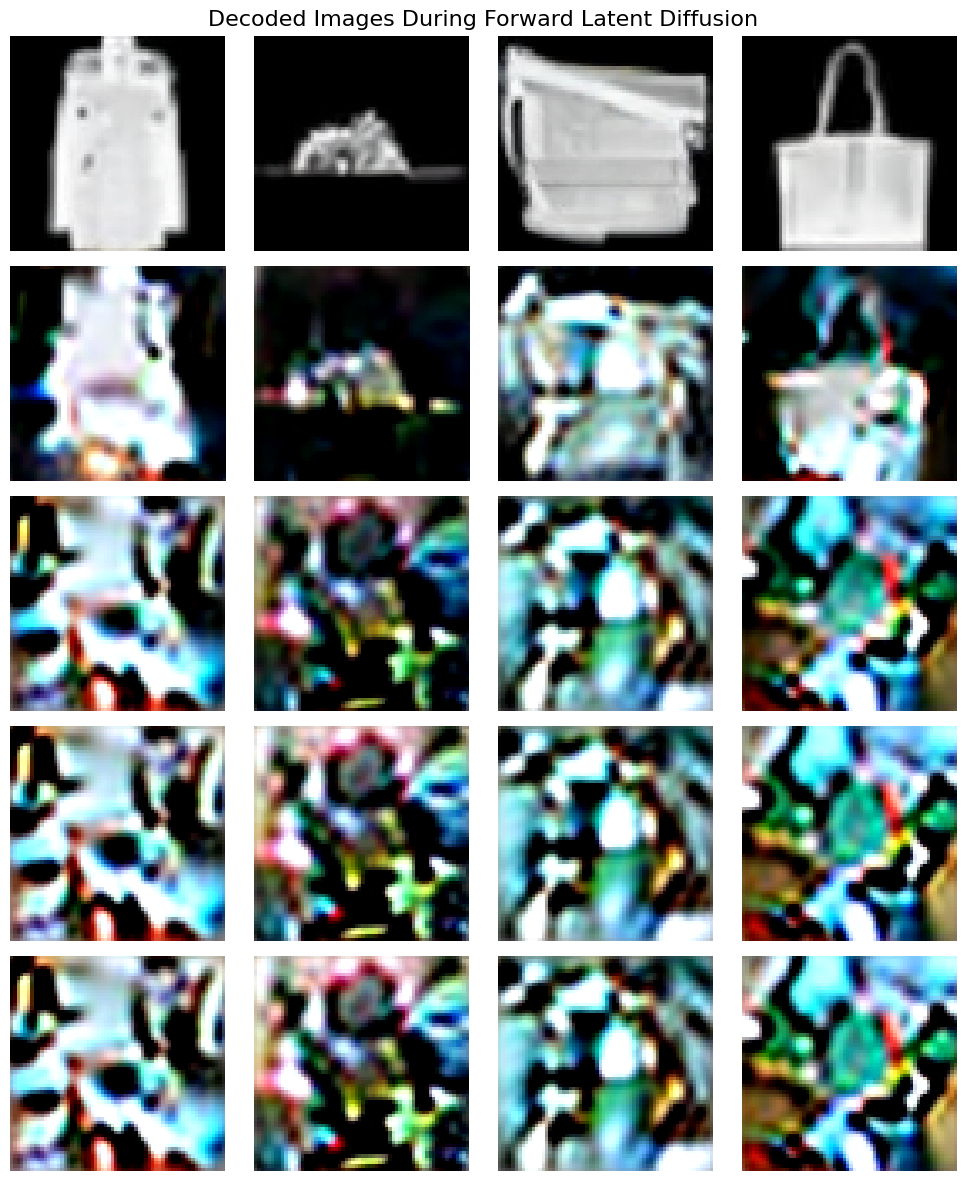

In [58]:
fig, axes = plt.subplots(5, 4, figsize=(10, 12))

for row, (timestep, decoded_batch) in enumerate(
    zip(display_timesteps, decoded_noisy_images)
):
    for col in range(4):
        image = denorm(
            decoded_batch[col]
        ).permute(1, 2, 0).cpu().numpy()

        axes[row, col].imshow(image)
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_ylabel(
                f"t={timestep}",
                fontsize=12
            )

plt.suptitle(
    "Decoded Images During Forward Latent Diffusion",
    fontsize=16
)

plt.tight_layout()
plt.show()

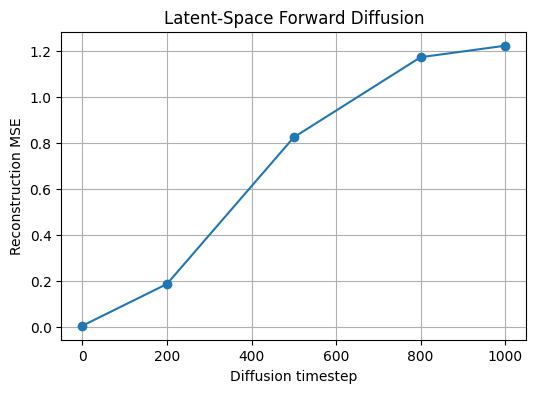

In [15]:
plt.figure(figsize=(6, 4))
plt.plot(display_timesteps, noise_level_mse, marker="o")
plt.xlabel("Diffusion timestep")
plt.ylabel("Reconstruction MSE")
plt.title("Latent-Space Forward Diffusion")
plt.grid(True)
plt.show()

3. Conditional Denoising U-Net

In [16]:
class SinusoidalTimeEmbedding(torch.nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()
        self.embedding_dim = embedding_dim

    def forward(self, timesteps):
        half_dim = self.embedding_dim // 2

        frequency_factor = torch.log(
            torch.tensor(10000.0, device=timesteps.device)
        ) / (half_dim - 1)

        frequencies = torch.exp(
            torch.arange(
                half_dim,
                device=timesteps.device
            ) * -frequency_factor
        )

        angles = timesteps.float()[:, None] * frequencies[None, :]

        embedding = torch.cat(
            [torch.sin(angles), torch.cos(angles)],
            dim=-1
        )

        return embedding

In [17]:
def valid_group_count(channels):
    """
    Choose a GroupNorm group count that divides the channel count.
    """
    for groups in [8, 4, 2, 1]:
        if channels % groups == 0:
            return groups
    return 1


class ResidualBlock(torch.nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()

        self.norm1 = torch.nn.GroupNorm(
            valid_group_count(in_channels),
            in_channels
        )
        self.conv1 = torch.nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        self.time_projection = torch.nn.Linear(
            time_dim,
            out_channels
        )

        self.norm2 = torch.nn.GroupNorm(
            valid_group_count(out_channels),
            out_channels
        )
        self.conv2 = torch.nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        self.activation = torch.nn.SiLU()

        self.skip = (
            torch.nn.Conv2d(in_channels, out_channels, kernel_size=1)
            if in_channels != out_channels
            else torch.nn.Identity()
        )

    def forward(self, x, time_embedding):
        residual = self.skip(x)

        h = self.norm1(x)
        h = self.activation(h)
        h = self.conv1(h)

        time_bias = self.time_projection(
            self.activation(time_embedding)
        )
        time_bias = time_bias[:, :, None, None]

        h = h + time_bias
        h = self.norm2(h)
        h = self.activation(h)
        h = self.conv2(h)

        return h + residual

In [18]:
class SelfAttention(torch.nn.Module):
    def __init__(self, channels, num_heads=4):
        super().__init__()

        assert channels % num_heads == 0, (
            "channels must be divisible by num_heads"
        )

        self.norm = torch.nn.GroupNorm(
            valid_group_count(channels),
            channels
        )

        self.attention = torch.nn.MultiheadAttention(
            embed_dim=channels,
            num_heads=num_heads,
            batch_first=True
        )

        self.feed_forward = torch.nn.Sequential(
            torch.nn.LayerNorm(channels),
            torch.nn.Linear(channels, channels * 2),
            torch.nn.SiLU(),
            torch.nn.Linear(channels * 2, channels)
        )

    def forward(self, x):
        batch_size, channels, height, width = x.shape

        normalized = self.norm(x)

        # Convert [B, C, H, W] to [B, H*W, C]
        tokens = normalized.flatten(2).transpose(1, 2)

        attention_output, _ = self.attention(
            tokens,
            tokens,
            tokens
        )

        tokens = tokens + attention_output
        tokens = tokens + self.feed_forward(tokens)

        # Convert back to [B, C, H, W]
        output = tokens.transpose(1, 2).reshape(
            batch_size,
            channels,
            height,
            width
        )

        return output + x

In [19]:
class DownBlock(torch.nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()

        self.residual = ResidualBlock(
            in_channels,
            out_channels,
            time_dim
        )

        self.downsample = torch.nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=4,
            stride=2,
            padding=1
        )

    def forward(self, x, time_embedding):
        skip = self.residual(x, time_embedding)
        downsampled = self.downsample(skip)

        return skip, downsampled


class UpBlock(torch.nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels, time_dim):
        super().__init__()

        self.upsample = torch.nn.ConvTranspose2d(
            in_channels,
            out_channels,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.residual = ResidualBlock(
            out_channels + skip_channels,
            out_channels,
            time_dim
        )

    def forward(self, x, skip, time_embedding):
        x = self.upsample(x)

        # Protect against small spatial-size mismatches
        if x.shape[-2:] != skip.shape[-2:]:
            x = torch.nn.functional.interpolate(
                x,
                size=skip.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        x = torch.cat([x, skip], dim=1)
        x = self.residual(x, time_embedding)

        return x

In [20]:
class LabelConditioner(torch.nn.Module):
    def __init__(self, num_classes, embedding_dim):
        super().__init__()


        self.null_label = num_classes

        self.embedding = torch.nn.Embedding(
            num_classes + 1,
            embedding_dim
        )

    def forward(self, labels, batch_size, device):
        if labels is None:
            labels = torch.full(
                (batch_size,),
                self.null_label,
                dtype=torch.long,
                device=device
            )
        else:
            labels = labels.to(device)

        return self.embedding(labels)

In [37]:
class CrossAttentionConditioning(torch.nn.Module):
    def __init__(self, channels, num_heads=4):
        super().__init__()

        assert channels % num_heads == 0

        self.query_norm = torch.nn.LayerNorm(channels)
        self.context_norm = torch.nn.LayerNorm(channels)

        self.cross_attention = torch.nn.MultiheadAttention(
            embed_dim=channels,
            num_heads=num_heads,
            batch_first=True
        )

        self.output_norm = torch.nn.LayerNorm(channels)

        self.feed_forward = torch.nn.Sequential(
            torch.nn.Linear(channels, channels * 2),
            torch.nn.SiLU(),
            torch.nn.Linear(channels * 2, channels)
        )

    def forward(self, x, context):
        batch_size, channels, height, width = x.shape

        spatial_tokens = x.flatten(2).transpose(1, 2)
        context_token = context.unsqueeze(1)

        queries = self.query_norm(spatial_tokens)
        keys_values = self.context_norm(context_token)

        attended, _ = self.cross_attention(
            query=queries,
            key=keys_values,
            value=keys_values
        )

        spatial_tokens = spatial_tokens + attended
        spatial_tokens = spatial_tokens + self.feed_forward(
            self.output_norm(spatial_tokens)
        )

        output = spatial_tokens.transpose(1, 2).reshape(
            batch_size,
            channels,
            height,
            width
        )

        return output

In [38]:
class CorrectedConditionalLatentUNet(torch.nn.Module):


    def __init__(
        self,
        in_channels=4,
        out_channels=4,
        base_channels=64,
        num_classes=10
    ):
        super().__init__()

        self.time_dim = base_channels * 4

        self.time_embedding = SinusoidalTimeEmbedding(
            base_channels
        )

        self.time_mlp = torch.nn.Sequential(
            torch.nn.Linear(
                base_channels,
                self.time_dim
            ),
            torch.nn.SiLU(),
            torch.nn.Linear(
                self.time_dim,
                self.time_dim
            )
        )

        self.label_conditioner = LabelConditioner(
            num_classes=num_classes,
            embedding_dim=self.time_dim
        )

        # Project class context from 256 dimensions to 64
        self.context_projection = torch.nn.Linear(
            self.time_dim,
            base_channels
        )

        # Input: [B, 4, 8, 8]
        self.input_projection = torch.nn.Conv2d(
            in_channels,
            base_channels,
            kernel_size=3,
            padding=1
        )

        # Move latent features to 16x16
        self.latent_upsample = torch.nn.ConvTranspose2d(
            base_channels,
            base_channels,
            kernel_size=4,
            stride=2,
            padding=1
        )

        # Required 16x16 self-attention and cross-attention
        self.attention_16 = SelfAttention(base_channels)

        self.cross_attention_16 = CrossAttentionConditioning(
            channels=base_channels,
            num_heads=4
        )

        # Encoder: 16x16 -> 8x8 -> 4x4 -> 2x2
        self.down1 = DownBlock(
            base_channels,
            base_channels,
            self.time_dim
        )

        self.down2 = DownBlock(
            base_channels,
            base_channels * 2,
            self.time_dim
        )

        self.down3 = DownBlock(
            base_channels * 2,
            base_channels * 4,
            self.time_dim
        )

        # Bottleneck
        self.bottleneck_block1 = ResidualBlock(
            base_channels * 4,
            base_channels * 4,
            self.time_dim
        )

        self.bottleneck_attention = SelfAttention(
            base_channels * 4
        )

        self.bottleneck_block2 = ResidualBlock(
            base_channels * 4,
            base_channels * 4,
            self.time_dim
        )

        # Decoder: 2x2 -> 4x4 -> 8x8 -> 16x16
        self.up3 = UpBlock(
            in_channels=base_channels * 4,
            skip_channels=base_channels * 4,
            out_channels=base_channels * 2,
            time_dim=self.time_dim
        )

        self.up2 = UpBlock(
            in_channels=base_channels * 2,
            skip_channels=base_channels * 2,
            out_channels=base_channels,
            time_dim=self.time_dim
        )

        self.up1 = UpBlock(
            in_channels=base_channels,
            skip_channels=base_channels,
            out_channels=base_channels,
            time_dim=self.time_dim
        )

        # Return from 16x16 to 8x8 latent resolution
        self.latent_downsample = torch.nn.Conv2d(
            base_channels,
            base_channels,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.output_projection = torch.nn.Sequential(
            torch.nn.GroupNorm(
                valid_group_count(base_channels),
                base_channels
            ),
            torch.nn.SiLU(),
            torch.nn.Conv2d(
                base_channels,
                out_channels,
                kernel_size=3,
                padding=1
            )
        )

    def forward(self, noisy_latents, timesteps, labels=None):
        batch_size = noisy_latents.shape[0]

        time_embedding = self.time_embedding(timesteps)
        time_embedding = self.time_mlp(time_embedding)

        label_embedding = self.label_conditioner(
            labels=labels,
            batch_size=batch_size,
            device=noisy_latents.device
        )

        conditioning = time_embedding + label_embedding
        context = self.context_projection(conditioning)

        x = self.input_projection(noisy_latents)
        x = self.latent_upsample(x)

        # Explicit 16x16 attention stages
        x = self.attention_16(x)
        x = self.cross_attention_16(x, context)

        skip1, x = self.down1(x, conditioning)
        skip2, x = self.down2(x, conditioning)
        skip3, x = self.down3(x, conditioning)

        x = self.bottleneck_block1(x, conditioning)
        x = self.bottleneck_attention(x)
        x = self.bottleneck_block2(x, conditioning)

        x = self.up3(x, skip3, conditioning)
        x = self.up2(x, skip2, conditioning)
        x = self.up1(x, skip1, conditioning)

        x = self.latent_downsample(x)

        return self.output_projection(x)

In [39]:
corrected_model = CorrectedConditionalLatentUNet().to(device)

test_timesteps = torch.randint(
    0,
    NUM_DIFFUSION_STEPS,
    (latents.shape[0],),
    device=device,
    dtype=torch.long
)

with torch.no_grad():
    corrected_output = corrected_model(
        noisy_latents=latents,
        timesteps=test_timesteps,
        labels=labels
    )

print("Corrected model created successfully")
print("Input shape:", latents.shape)
print("Output shape:", corrected_output.shape)

corrected_parameter_count = sum(
    parameter.numel()
    for parameter in corrected_model.parameters()
)

print(
    f"Trainable parameters: "
    f"{corrected_parameter_count:,}"
)

Corrected model created successfully
Input shape: torch.Size([8, 4, 8, 8])
Output shape: torch.Size([8, 4, 8, 8])
Trainable parameters: 7,748,100


In [40]:
model = corrected_model

criterion = torch.nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

corrected_training_losses = []

print("Corrected model optimizer ready")

Corrected model optimizer ready


In [41]:
corrected_latent_loader = DataLoader(
    latent_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

corrected_training_losses = []

print("Starting corrected-model training...")

for epoch in range(NUM_EPOCHS):
    model.train()
    running_loss = 0.0

    progress_bar = tqdm(
        corrected_latent_loader,
        desc=f"Corrected epoch {epoch + 1}/{NUM_EPOCHS}"
    )

    for clean_latents, batch_labels in progress_bar:
        clean_latents = clean_latents.to(
            device,
            non_blocking=True
        )
        batch_labels = batch_labels.to(
            device,
            non_blocking=True
        )

        batch_size = clean_latents.shape[0]

        timesteps = torch.randint(
            0,
            NUM_DIFFUSION_STEPS,
            (batch_size,),
            device=device,
            dtype=torch.long
        )

        noisy_latents, noise_target = q_sample(
            clean_latents,
            timesteps
        )

        labels_for_model = batch_labels.clone()

        drop_mask = (
            torch.rand(batch_size, device=device)
            < DROP_LABEL_PROBABILITY
        )

        labels_for_model[drop_mask] = 10

        noise_prediction = model(
            noisy_latents,
            timesteps,
            labels_for_model
        )

        loss = criterion(
            noise_prediction,
            noise_target
        )

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        progress_bar.set_postfix(
            loss=f"{loss.item():.5f}"
        )

    epoch_loss = (
        running_loss / len(corrected_latent_loader)
    )

    corrected_training_losses.append(epoch_loss)

    print(
        f"Corrected epoch {epoch + 1}/{NUM_EPOCHS} "
        f"- Average loss: {epoch_loss:.6f}"
    )

Starting corrected-model training...


Corrected epoch 1/50:   0%|          | 0/469 [00:00<?, ?it/s]

Corrected epoch 1/50 - Average loss: 0.337214


Corrected epoch 2/50:   0%|          | 0/469 [00:00<?, ?it/s]

Corrected epoch 2/50 - Average loss: 0.179545


...

Corrected epoch 48/50 - Average loss: 0.108462


Corrected epoch 49/50:   0%|          | 0/469 [00:00<?, ?it/s]

Corrected epoch 49/50 - Average loss: 0.108114


Corrected epoch 50/50:   0%|          | 0/469 [00:00<?, ?it/s]

Corrected epoch 50/50 - Average loss: 0.107927


In [42]:
corrected_checkpoint_path = (
    "/content/HW9_latent_diffusion_corrected_2733.pt"
)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "training_losses": corrected_training_losses,
        "sid4": SID4,
        "seed": SEED,
        "latent_scale": LATENT_SCALE,
        "num_diffusion_steps": NUM_DIFFUSION_STEPS,
        "guidance_scale": GUIDANCE_SCALE,
        "architecture": "CorrectedConditionalLatentUNet",
        "cross_attention": True,
        "attention_resolution": "16x16 plus bottleneck",
    },
    corrected_checkpoint_path
)

print("Corrected checkpoint saved to:")
print(corrected_checkpoint_path)

Corrected checkpoint saved to:
/content/HW9_latent_diffusion_corrected_2733.pt


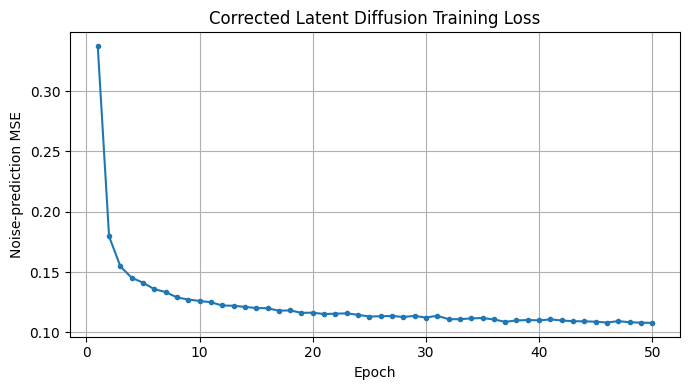

In [43]:
plt.figure(figsize=(7, 4))

plt.plot(
    range(1, len(corrected_training_losses) + 1),
    corrected_training_losses,
    marker="o",
    markersize=3
)

plt.xlabel("Epoch")
plt.ylabel("Noise-prediction MSE")
plt.title("Corrected Latent Diffusion Training Loss")
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "/content/HW9_corrected_training_loss_2733.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [48]:
# Reverse-diffusion coefficients

alpha_bars_prev = torch.cat([
    torch.ones(1, device=device),
    alpha_bars[:-1]
])

GUIDANCE_SCALE = 3.0


@torch.no_grad()
def reverse_diffusion_step(
    model,
    noisy_latents,
    timestep,
    labels,
    guidance_scale=3.0
):
    batch_size = noisy_latents.shape[0]

    timestep_tensor = torch.full(
        (batch_size,),
        timestep,
        device=noisy_latents.device,
        dtype=torch.long
    )

    # Conditional and unconditional predictions
    noise_conditional = model(
        noisy_latents,
        timestep_tensor,
        labels
    )

    noise_unconditional = model(
        noisy_latents,
        timestep_tensor,
        None
    )

    # Classifier-free guidance:
    # epsilon = (1+w)*epsilon_cond - w*epsilon_uncond
    predicted_noise = (
        (1.0 + guidance_scale) * noise_conditional
        - guidance_scale * noise_unconditional
    )

    alpha_t = alphas[timestep]
    alpha_bar_t = alpha_bars[timestep]
    alpha_bar_previous = alpha_bars_prev[timestep]
    beta_t = betas[timestep]

    sqrt_one_minus_alpha_bar_t = (
        sqrt_one_minus_alpha_bars[timestep]
    )

    mean = (
        1.0 / torch.sqrt(alpha_t)
    ) * (
        noisy_latents
        - (
            (1.0 - alpha_t)
            / sqrt_one_minus_alpha_bar_t
        ) * predicted_noise
    )

    if timestep > 0:
        posterior_variance = (
            beta_t
            * (1.0 - alpha_bar_previous)
            / (1.0 - alpha_bar_t)
        )

        random_noise = torch.randn_like(noisy_latents)

        previous_latents = (
            mean
            + torch.sqrt(posterior_variance) * random_noise
        )
    else:
        previous_latents = mean

    return previous_latents

In [49]:
torch.manual_seed(SEED)

sample_labels = torch.arange(
    10,
    device=device
).repeat(7)[:64]

sample_latents = torch.randn(
    (64, 4, 8, 8),
    device=device
)

model.eval()

with torch.no_grad():
    for timestep in tqdm(
        reversed(range(NUM_DIFFUSION_STEPS)),
        total=NUM_DIFFUSION_STEPS,
        desc="Corrected reverse diffusion"
    ):
        sample_latents = reverse_diffusion_step(
            model=model,
            noisy_latents=sample_latents,
            timestep=timestep,
            labels=sample_labels,
            guidance_scale=GUIDANCE_SCALE
        )

print("Corrected latent samples:", sample_latents.shape)

Corrected reverse diffusion:   0%|          | 0/1000 [00:00<?, ?it/s]

Corrected latent samples: torch.Size([64, 4, 8, 8])


In [50]:
with torch.no_grad():
    corrected_generated_images = vae.decode(
        sample_latents / LATENT_SCALE
    ).sample

corrected_generated_images = denorm(
    corrected_generated_images
)

print(
    "Corrected generated image shape:",
    corrected_generated_images.shape
)

Corrected generated image shape: torch.Size([64, 3, 64, 64])


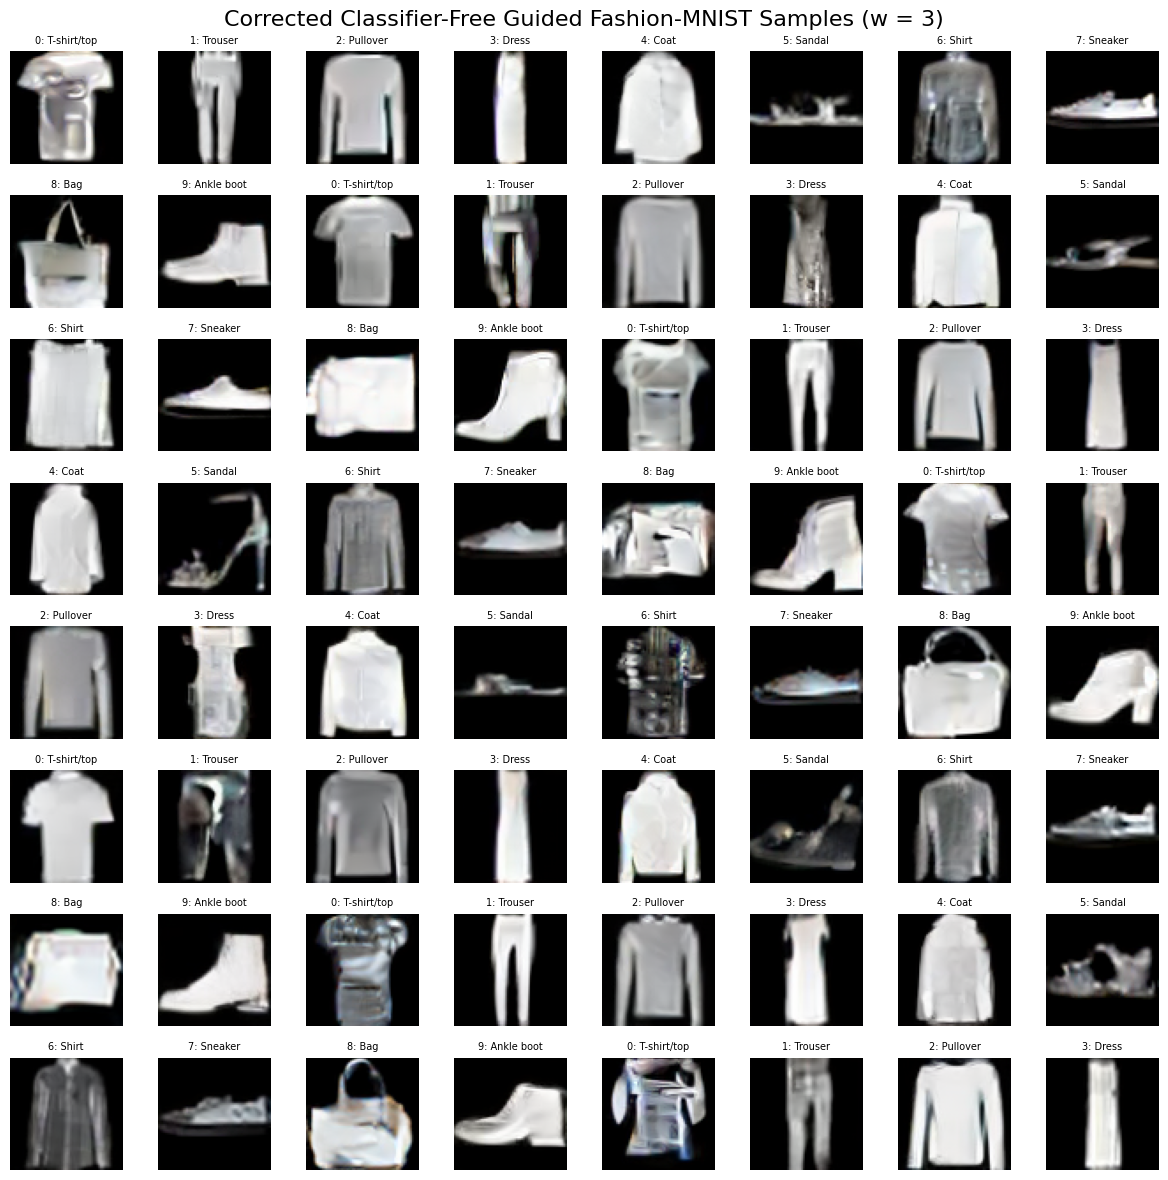

Saved corrected grid to: /content/HW9_corrected_samples_2733.png


In [51]:
fig, axes = plt.subplots(8, 8, figsize=(12, 12))

for i, ax in enumerate(axes.flat):
    image = (
        corrected_generated_images[i]
        .permute(1, 2, 0)
        .cpu()
        .numpy()
    )

    ax.imshow(image)
    ax.set_title(
        f"{sample_labels[i].item()}: "
        f"{dataset.classes[sample_labels[i].item()]}",
        fontsize=7
    )
    ax.axis("off")

plt.suptitle(
    "Corrected Classifier-Free Guided "
    "Fashion-MNIST Samples (w = 3)",
    fontsize=16
)

plt.tight_layout()

corrected_grid_path = (
    "/content/HW9_corrected_samples_2733.png"
)

plt.savefig(
    corrected_grid_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved corrected grid to:", corrected_grid_path)

In [53]:
from google.colab import files

files.download(
    "/content/HW9_latent_diffusion_corrected_2733.pt"
)

files.download(
    "/content/HW9_corrected_samples_2733.png"
)

files.download(
    "/content/HW9_corrected_training_loss_2733.png"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>